## Install packages

In [2]:
!pip install -q ultralytics opendatasets pandas legacy-cgi

## Imports

In [3]:
import gc
import shutil
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import opendatasets as od
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Folders and constants

In [4]:
DATA_DIR   = Path('/root/Dataset')
RUNS_DIR   = Path('/root/runs')
EXPORT_DIR = Path('/root/exports')
PLOT_DIR   = Path('/root/plots')
DATA_YAML  = Path('/root/kitchenware.yaml')

# /workspace is the persistent volume on RunPod, so copies kept there survive a pod restart
SAVE_DIR = Path('/workspace/kitchenware_results') if Path('/workspace').exists() else Path('/root/kitchenware_results')

for folder in (DATA_DIR, RUNS_DIR, EXPORT_DIR, PLOT_DIR, SAVE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATASET_URL = 'https://www.kaggle.com/datasets/raunakgola/kitchenware-object-detection-dataset-yolo-format'
CLASS_NAMES = ['plate', 'spoon', 'fork', 'knife', 'cup', 'glass']
MODEL_NAMES = ['yolo26n', 'yolo26s']
IMGSZ = 640

# colours used in every comparison plot
MODEL_COLORS   = {'yolo26n': '#1b9e77', 'yolo26s': '#d95f02'}
VARIANT_COLORS = {'FP32 (.pt)': '#4c78a8', 'w8a32': '#54a24b', 'INT8': '#e45756'}

plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False})


## Download the dataset

In [5]:
od.download(DATASET_URL, data_dir=str(DATA_DIR))

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds


Your Kaggle username:  raunakgola
Your Kaggle Key:  ········


Dataset URL: https://www.kaggle.com/datasets/raunakgola/kitchenware-object-detection-dataset-yolo-format


100%|██████████| 1.57G/1.57G [00:41<00:00, 40.4MB/s]


## Write the data yaml

In [6]:
ROOT = next(DATA_DIR.glob('*/Dataset'))

DATA_YAML.write_text(
    f"path: {ROOT}\n"
    "train: train/images\n"
    "val: val/images\n"
    f"nc: {len(CLASS_NAMES)}\n"
    f"names: {CLASS_NAMES}\n"
)

n_train = len(list((ROOT / 'train' / 'images').glob('*')))
n_val   = len(list((ROOT / 'val' / 'images').glob('*')))
print(DATA_YAML.read_text())
print(f'train images: {n_train} | val images: {n_val}')


path: /root/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset
train: train/images
val: val/images
nc: 6
names: ['plate', 'spoon', 'fork', 'knife', 'cup', 'glass']

train images: 7187 | val images: 1797


## Check the GPU

In [7]:
assert torch.cuda.is_available(), 'No GPU found'
gpu = torch.cuda.get_device_properties(0)
GPU_GB = gpu.total_memory / 1024**3
print(f'{gpu.name} | {GPU_GB:.1f} GB')


NVIDIA GeForce RTX 4090 | 23.5 GB


## Smoke test: yolo26n, batch 48, 15 epochs

In [8]:
# mosaic stays on for every image and every epoch (close_mosaic=0),
# so the timing and memory numbers are the worst case, not a flattering one
torch.cuda.reset_peak_memory_stats()
t0 = time.time()

smoke = YOLO('yolo26n.pt')
smoke.train(
    data=str(DATA_YAML), epochs=15, patience=5, batch=48, imgsz=IMGSZ,
    optimizer='AdamW', lr0=0.0002, weight_decay=0.0005, cos_lr=True,
    mosaic=1.0, close_mosaic=0, mixup=0.1,
    cache='ram', workers=12, device=0,
    project=str(RUNS_DIR), name='smoke_yolo26n', exist_ok=True,
    plots=False, save_period=-1,
)

smoke_wall = time.time() - t0


Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=48, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/root/kitchenware.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_yolo26n, nbs=64, nms=None, opset=None, optimize=Fa

## Smoke test summary

In [9]:
RATE_PER_HOUR = 0.89
BALANCE = 8.69

log = pd.read_csv(RUNS_DIR / 'smoke_yolo26n' / 'results.csv')
log.columns = log.columns.str.strip()

epochs_run = len(log)
best_map   = log['metrics/mAP50-95(B)'].max()
train_secs = log['time'].iloc[-1] if 'time' in log else smoke_wall
sec_per_epoch = train_secs / epochs_run
peak_gb = torch.cuda.max_memory_reserved(0) / 1024**3

full_hours = sec_per_epoch * 150 / 3600
full_cost  = full_hours * RATE_PER_HOUR

print(f'epochs run          : {epochs_run} / 15')
print(f'best mAP50-95       : {best_map:.4f}')
print(f'peak GPU memory     : {peak_gb:.1f} GB of {GPU_GB:.1f} GB')
print(f'seconds per epoch   : {sec_per_epoch:.0f}')
print(f'150 epochs (worst)  : {full_hours:.2f} h  ->  ${full_cost:.2f}  (balance ${BALANCE})')
print('batch 48 fits' if peak_gb < GPU_GB * 0.9 else 'batch 48 is too tight, drop to 40')

epochs run          : 15 / 15
best mAP50-95       : 0.9438
peak GPU memory     : 9.2 GB of 23.5 GB
seconds per epoch   : 25
150 epochs (worst)  : 1.05 h  ->  $0.93  (balance $8.69)
batch 48 fits


## Free the GPU

In [10]:
del smoke
gc.collect()
torch.cuda.empty_cache()

## Final training settings

In [14]:
COMMON = dict(
    data=str(DATA_YAML), epochs=150, patience=20, imgsz=IMGSZ,
    optimizer='AdamW', weight_decay=0.0005, cos_lr=True,
    close_mosaic=12, mixup=0.1, save_period=10,
    cache='ram', workers=12, device=0,
    project=str(RUNS_DIR), exist_ok=True, plots=True,
)

PER_MODEL = {
    'yolo26n': dict(weights='yolo26n.pt', batch=64, lr0=0.0002,   mosaic=0.52),
    'yolo26s': dict(weights='yolo26s.pt', batch=48, lr0=0.000218, mosaic=0.238),
}

train_secs = {}
best_pt = {name: RUNS_DIR / name / 'weights' / 'best.pt' for name in MODEL_NAMES}

## Train yolo26n

In [13]:
cfg = PER_MODEL['yolo26n']
t0 = time.time()

model = YOLO(cfg['weights'])
model.train(**COMMON, name='yolo26n', batch=cfg['batch'], lr0=cfg['lr0'], mosaic=cfg['mosaic'])

train_secs['yolo26n'] = time.time() - t0
print(f"yolo26n trained in {train_secs['yolo26n'] / 3600:.2f} h")

# keep a copy on the persistent volume in case the pod dies
shutil.copytree(RUNS_DIR / 'yolo26n', SAVE_DIR / 'runs' / 'yolo26n', dirs_exist_ok=True)

Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=12, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/root/kitchenware.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.52, multi_scale=0.0, name=yolo26n, nbs=64, nms=None, opset=None, optimize=False

PosixPath('/workspace/kitchenware_results/runs/yolo26n')

## Train yolo26s

In [15]:
del model
gc.collect()
torch.cuda.empty_cache()

cfg = PER_MODEL['yolo26s']
t0 = time.time()

model = YOLO(cfg['weights'])
model.train(**COMMON, name='yolo26s', batch=cfg['batch'], lr0=cfg['lr0'], mosaic=cfg['mosaic'])

train_secs['yolo26s'] = time.time() - t0
print(f"yolo26s trained in {train_secs['yolo26s'] / 3600:.2f} h")

shutil.copytree(RUNS_DIR / 'yolo26s', SAVE_DIR / 'runs' / 'yolo26s', dirs_exist_ok=True)


Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=48, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=12, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/root/kitchenware.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.000218, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.238, multi_scale=0.0, name=yolo26s, nbs=64, nms=None, opset=None, optimize=Fa

PosixPath('/workspace/kitchenware_results/runs/yolo26s')

## Training curves, both models in one figure

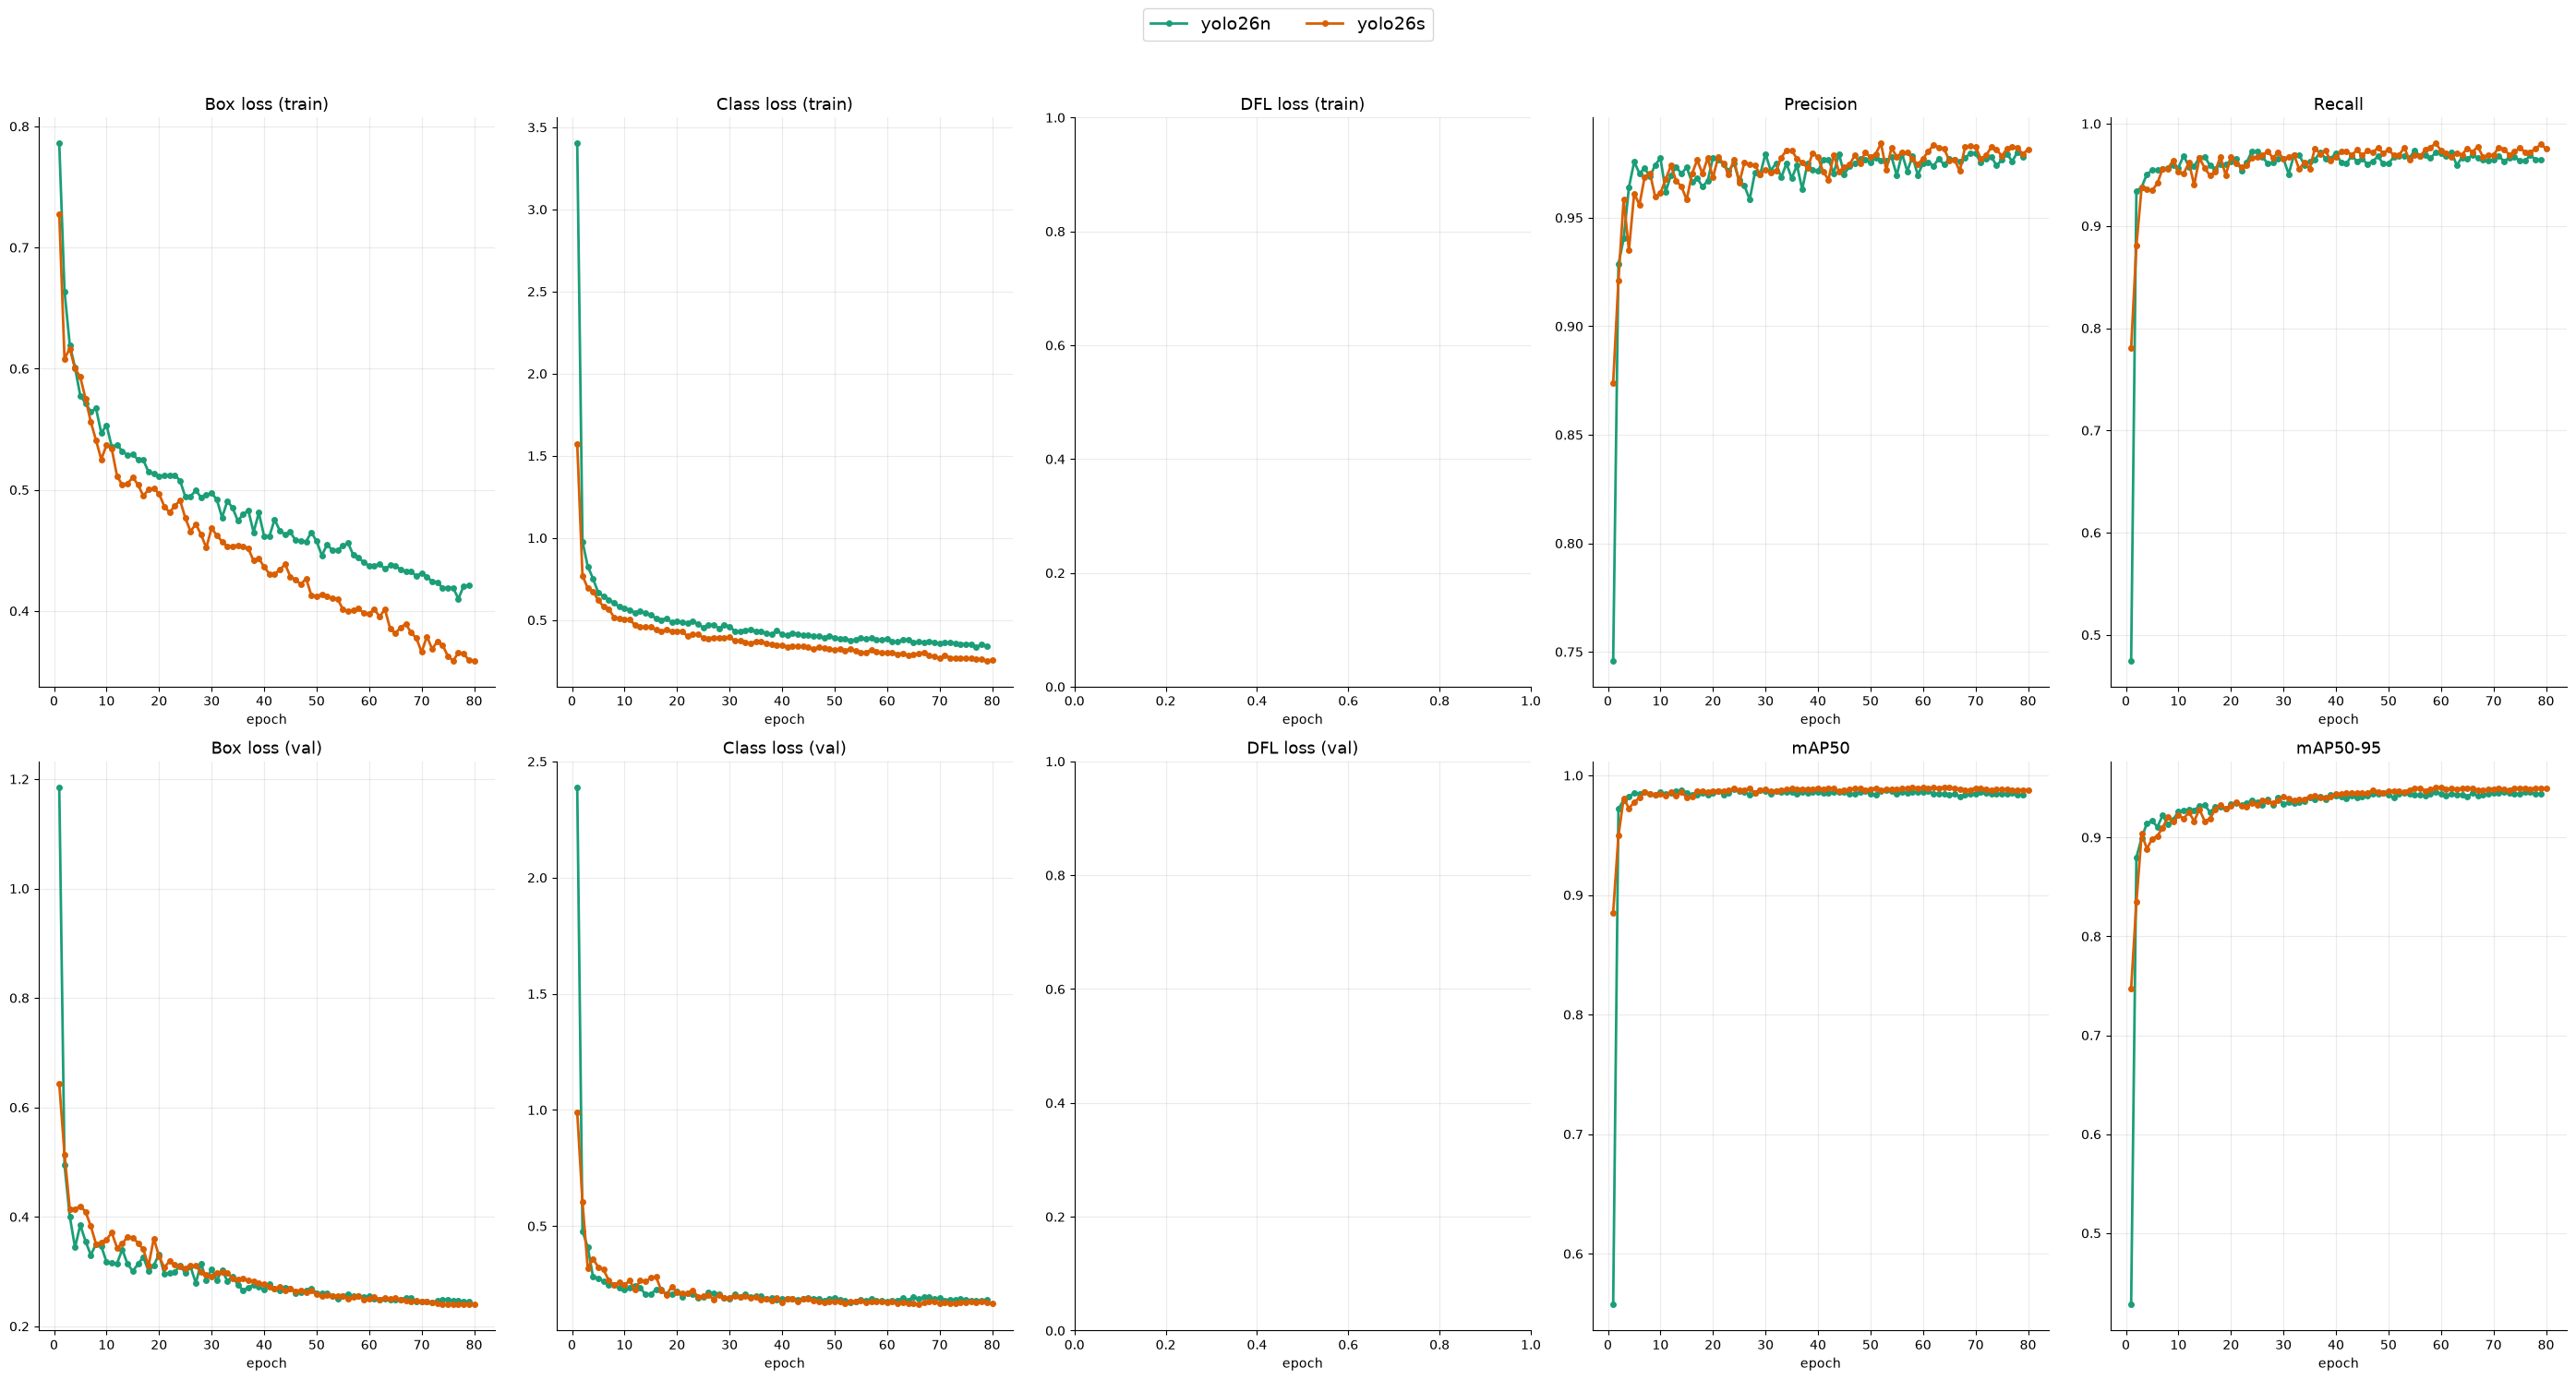

In [19]:
def load_log(name):
    df = pd.read_csv(RUNS_DIR / name / 'results.csv')
    df.columns = df.columns.str.strip()
    return df

logs = {name: load_log(name) for name in MODEL_NAMES}

PANELS = [
    ('train/box_loss', 'Box loss (train)'),
    ('train/cls_loss', 'Class loss (train)'),
    ('train/dfl_loss', 'DFL loss (train)'),
    ('metrics/precision(B)', 'Precision'),
    ('metrics/recall(B)', 'Recall'),
    ('val/box_loss', 'Box loss (val)'),
    ('val/cls_loss', 'Class loss (val)'),
    ('val/dfl_loss', 'DFL loss (val)'),
    ('metrics/mAP50(B)', 'mAP50'),
    ('metrics/mAP50-95(B)', 'mAP50-95'),
]

fig, axes = plt.subplots(2, 5, figsize=(28, 15))
for ax, (col, title) in zip(axes.ravel(), PANELS):
    for name, df in logs.items():
        if col not in df:
            continue
        ax.plot(df['epoch'], df[col], color=MODEL_COLORS[name], lw=2, marker='o', ms=4, label=name)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('epoch')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, fontsize=14, frameon=True)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(PLOT_DIR / 'results_both_models.png', dpi=130)
plt.show()


## Zoomed mAP curves

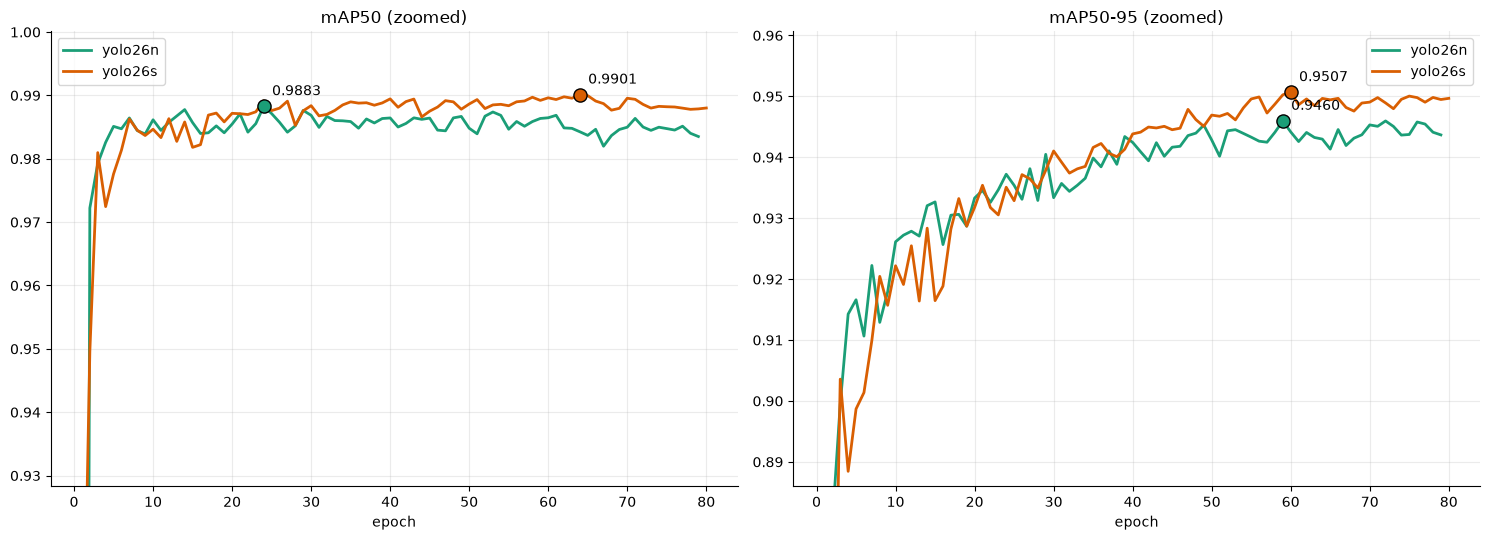

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, col, title in zip(axes, ['metrics/mAP50(B)', 'metrics/mAP50-95(B)'], ['mAP50', 'mAP50-95']):
    for name, df in logs.items():
        ax.plot(df['epoch'], df[col], color=MODEL_COLORS[name], lw=2, label=name)
        top = df[col].idxmax()
        ax.scatter(df.loc[top, 'epoch'], df.loc[top, col], s=90, color=MODEL_COLORS[name], edgecolor='black', zorder=3)
        ax.annotate(f"{df.loc[top, col]:.4f}", (df.loc[top, 'epoch'], df.loc[top, col]),
                    textcoords='offset points', xytext=(6, 8), fontsize=10)
    best_of_both = max(df[col].max() for df in logs.values())
    worst_of_both = min(df[col].max() for df in logs.values())
    ax.set_ylim(worst_of_both - 0.06, best_of_both + 0.01)
    ax.set_title(f'{title} (zoomed)')
    ax.set_xlabel('epoch')
    ax.legend()

fig.tight_layout()
fig.savefig(PLOT_DIR / 'map_zoomed.png', dpi=130)
plt.show()

## Confusion matrix, PR and F1 side by side

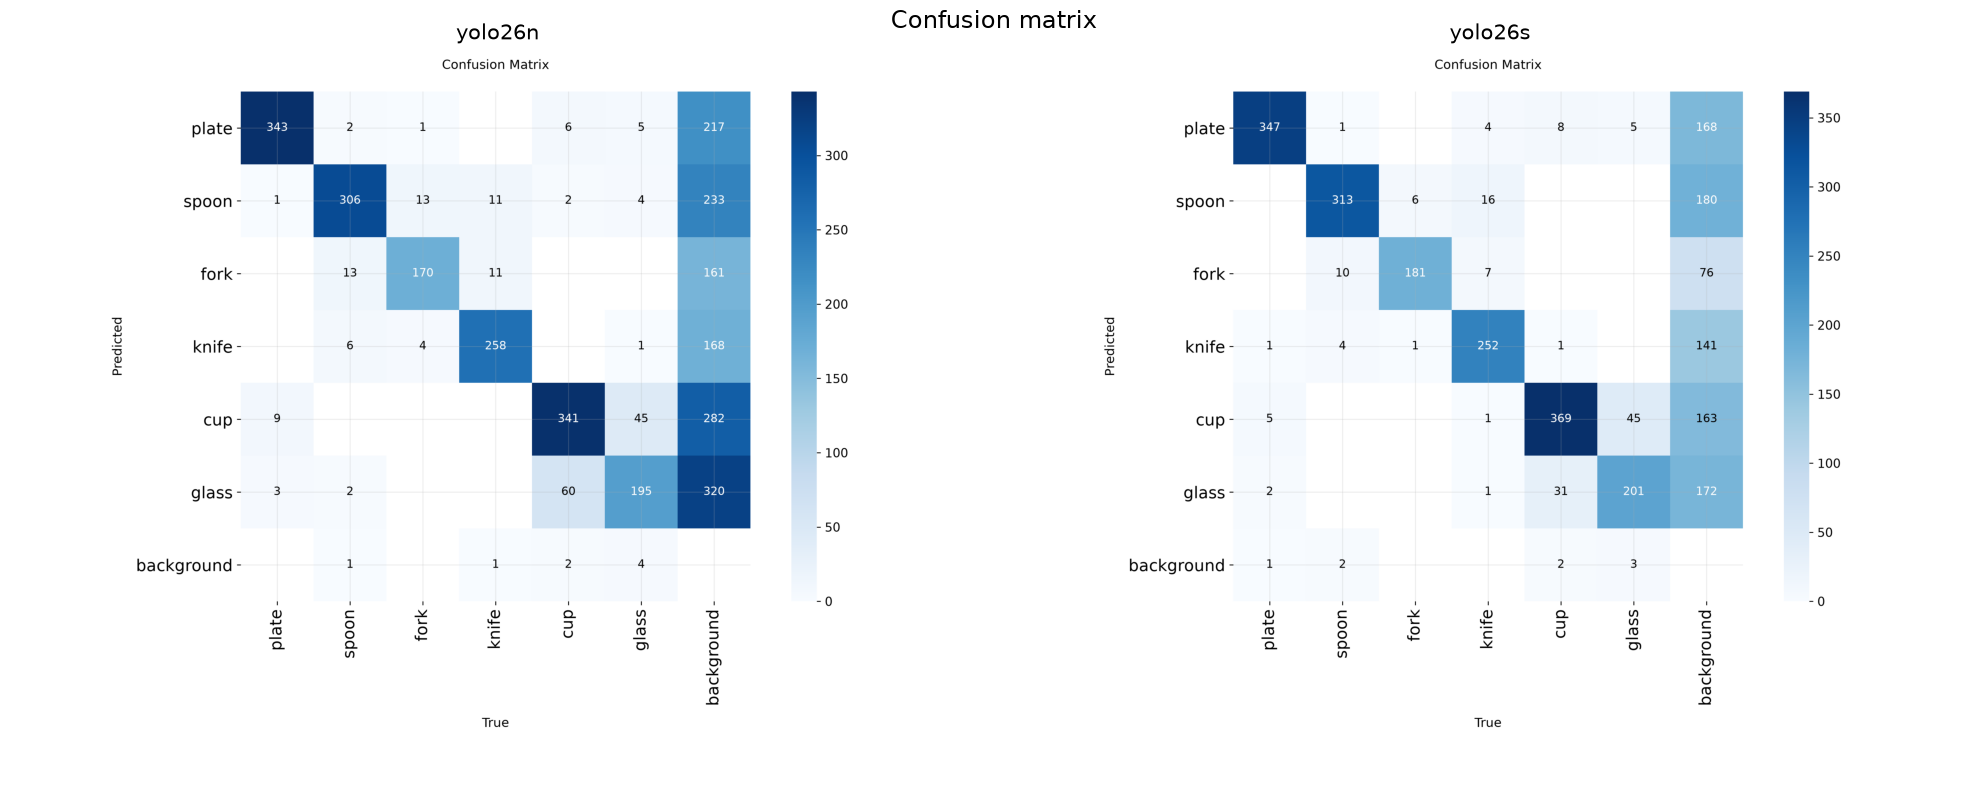

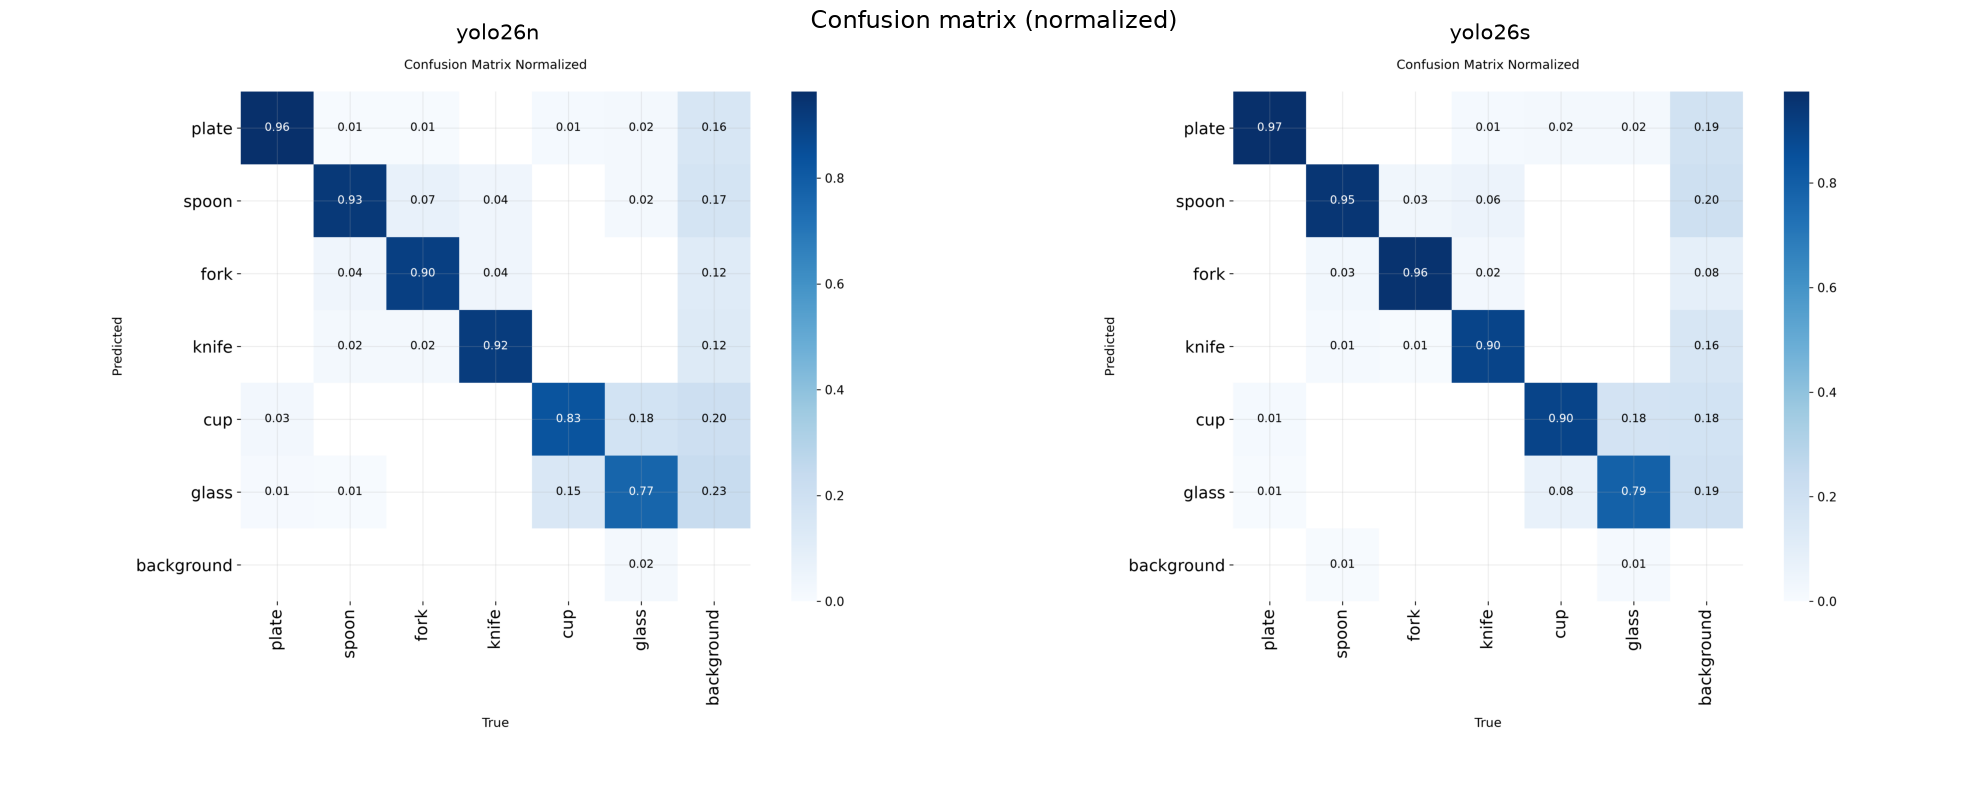

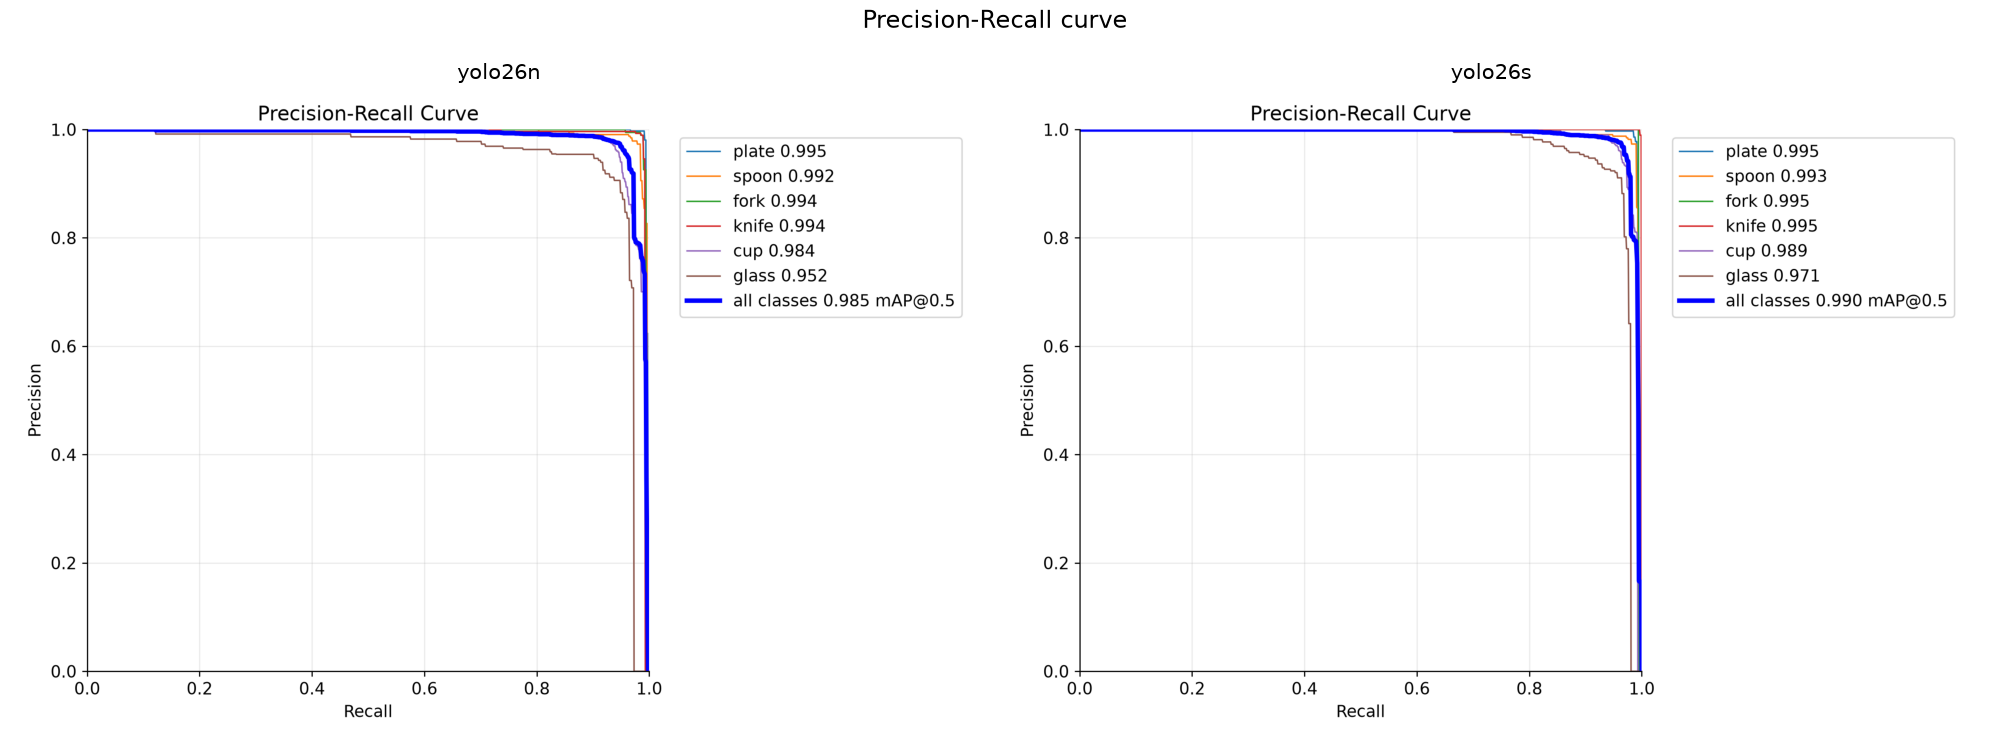

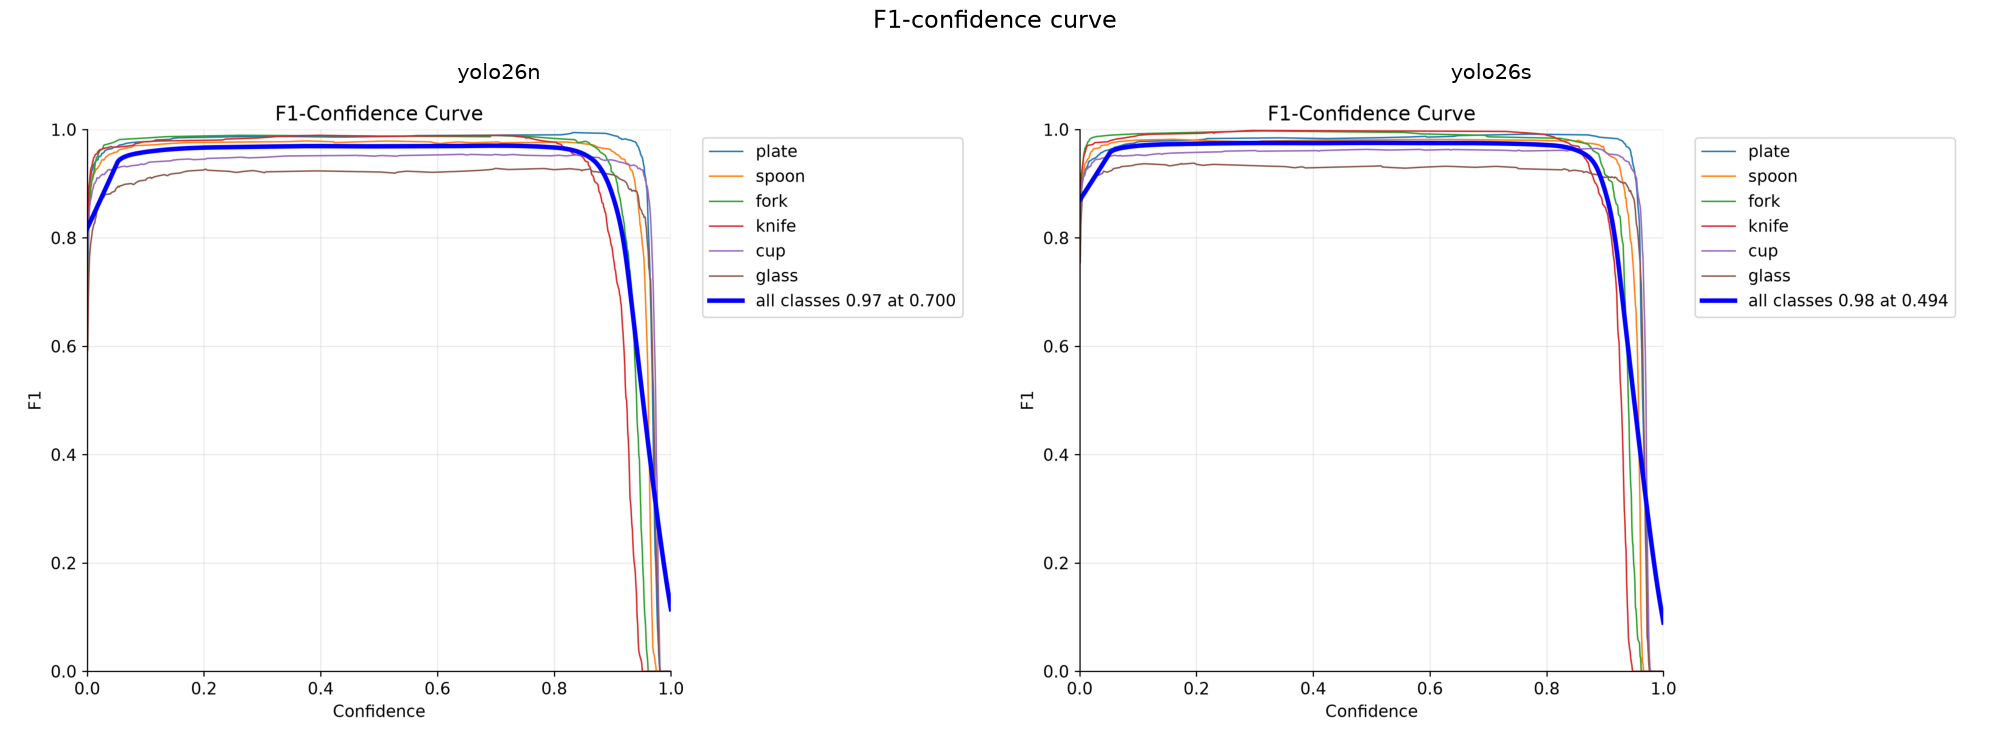

In [21]:
SIDE_BY_SIDE = [
    ('confusion_matrix.png', 'Confusion matrix'),
    ('confusion_matrix_normalized.png', 'Confusion matrix (normalized)'),
    ('BoxPR_curve.png', 'Precision-Recall curve'),
    ('BoxF1_curve.png', 'F1-confidence curve'),
]

for fname, title in SIDE_BY_SIDE:
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    for ax, name in zip(axes, MODEL_NAMES):
        img_path = RUNS_DIR / name / fname
        if img_path.exists():
            ax.imshow(plt.imread(img_path))
        else:
            ax.text(0.5, 0.5, f'{fname} not found', ha='center', va='center')
        ax.set_title(name, fontsize=15)
        ax.axis('off')
    fig.suptitle(title, fontsize=17)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f'compare_{Path(fname).stem}.png', dpi=130)
    plt.show()


## Validation helper

In [22]:
def evaluate(weights, device, batch):
    t0 = time.time()
    m = YOLO(str(weights), task='detect').val(
        data=str(DATA_YAML), split='val', imgsz=IMGSZ,
        batch=batch, device=device, plots=False, verbose=False,
    )
    return dict(
        map50=float(m.box.map50),
        map5095=float(m.box.map),
        precision=float(m.box.mp),
        recall=float(m.box.mr),
        per_class=[float(v) for v in m.box.maps],
        infer_ms=float(m.speed['inference']),
        val_secs=time.time() - t0,
        size_mb=Path(weights).stat().st_size / 1024**2,
    )

rows = []


## FP32 validation on the full val set

In [23]:
for name in MODEL_NAMES:
    r = evaluate(best_pt[name], device=0, batch=32)
    rows.append(dict(model=name, variant='FP32 (.pt)', device='GPU', export_secs=0.0, **r))
    print(f"{name} FP32: mAP50-95 {r['map5095']:.4f} | mAP50 {r['map50']:.4f}")


Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1991.3±661.6 MB/s, size: 229.1 KB)
val: Scanning /root/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset/val/labels.cache... 1797 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1797/1797 538.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 57/57 5.9it/s 9.7s<0.2s
                   all       1797       1820      0.977      0.963      0.985      0.946
Speed: 0.6ms preprocess, 0.7ms inference, 0.0ms loss, 0.7ms postprocess per image
yolo26n FP32: mAP50-95 0.9464 | mAP50 0.9851
Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image ac

## Export helper

In [24]:
exports = {}

def export_litert(name, variant, **quant_args):
    t0 = time.time()
    out = Path(YOLO(str(best_pt[name])).export(format='litert', imgsz=IMGSZ, batch=1, **quant_args))

    # the exporter may hand back a folder or the file itself
    if out.is_dir():
        out = max(out.glob('*.tflite'), key=lambda p: p.stat().st_mtime)

    target = EXPORT_DIR / f'{name}_{variant}.tflite'
    shutil.copy(out, target)

    exports[(name, variant)] = dict(path=target, secs=time.time() - t0)
    print(f'{name} {variant}: {target.stat().st_size / 1024**2:.2f} MB in {exports[(name, variant)]["secs"]:.0f} s')


## Export w8a32 (no calibration needed)

In [26]:
!pip install -q "torchao==0.17.0"

In [1]:
import gc
import shutil
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import opendatasets as od
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO

DATA_DIR   = Path('/root/Dataset')
RUNS_DIR   = Path('/root/runs')
EXPORT_DIR = Path('/root/exports')
PLOT_DIR   = Path('/root/plots')
DATA_YAML  = Path('/root/kitchenware.yaml')

SAVE_DIR = Path('/workspace/kitchenware_results') if Path('/workspace').exists() else Path('/root/kitchenware_results')

for folder in (DATA_DIR, RUNS_DIR, EXPORT_DIR, PLOT_DIR, SAVE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['plate', 'spoon', 'fork', 'knife', 'cup', 'glass']
MODEL_NAMES = ['yolo26n', 'yolo26s']
IMGSZ = 640

MODEL_COLORS   = {'yolo26n': '#1b9e77', 'yolo26s': '#d95f02'}
VARIANT_COLORS = {'FP32 (.pt)': '#4c78a8', 'w8a32': '#54a24b', 'INT8': '#e45756'}

plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False})

train_secs = {}
best_pt = {name: RUNS_DIR / name / 'weights' / 'best.pt' for name in MODEL_NAMES}

def evaluate(weights, device, batch):
    t0 = time.time()
    m = YOLO(str(weights), task='detect').val(
        data=str(DATA_YAML), split='val', imgsz=IMGSZ,
        batch=batch, device=device, plots=False, verbose=False,
    )
    return dict(
        map50=float(m.box.map50),
        map5095=float(m.box.map),
        precision=float(m.box.mp),
        recall=float(m.box.mr),
        per_class=[float(v) for v in m.box.maps],
        infer_ms=float(m.speed['inference']),
        val_secs=time.time() - t0,
        size_mb=Path(weights).stat().st_size / 1024**2,
    )

rows = []

for name in MODEL_NAMES:
    r = evaluate(best_pt[name], device=0, batch=32)
    rows.append(dict(model=name, variant='FP32 (.pt)', device='GPU', export_secs=0.0, **r))
    print(f"{name} FP32: mAP50-95 {r['map5095']:.4f} | mAP50 {r['map50']:.4f}")

import litert_torch
print('litert_torch OK')

exports = {}

def export_litert(name, variant, **quant_args):
    t0 = time.time()
    out = Path(YOLO(str(best_pt[name])).export(format='litert', imgsz=IMGSZ, batch=1, **quant_args))

    if out.is_dir():
        out = max(out.glob('*.tflite'), key=lambda p: p.stat().st_mtime)

    target = EXPORT_DIR / f'{name}_{variant}.tflite'
    shutil.copy(out, target)

    exports[(name, variant)] = dict(path=target, secs=time.time() - t0)
    print(f'{name} {variant}: {target.stat().st_size / 1024**2:.2f} MB in {exports[(name, variant)]["secs"]:.0f} s')

Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2049.7±396.3 MB/s, size: 220.3 KB)
val: Scanning /root/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset/val/labels.cache... 1797 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1797/1797 342.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 57/57 10.8it/s 5.3s0.2s
                   all       1797       1820      0.977      0.963      0.985      0.946
Speed: 0.6ms preprocess, 0.6ms inference, 0.0ms loss, 0.6ms postprocess per image
yolo26n FP32: mAP50-95 0.9464 | mAP50 0.9851
Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image ac

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.8.0+cu128).


litert_torch OK


In [2]:
for name in MODEL_NAMES:
    export_litert(name, 'w8a32', quantize='w8a32')


Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CPU (AMD EPYC 7452 32-Core Processor)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/root/runs/yolo26n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (5.2 MB)

LiteRT: starting export with litert_torch 0.9.4...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

(00:02) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:01)

...

(00:00) [START] Write Model to /root/runs/yolo26s/weights/best_w8a32.tflite

(00:00) [ DONE] Write Model to /root/runs/yolo26s/weights/best_w8a32.tflite (+00:00)

LiteRT: applying dynamic INT8 quantization (int8 weights + FP32 activations)...


Applying Transformations to tensors:: 100%|██████████| 659/659 [00:00<00:00, 148628.61it/s]


Model name: /root/runs/yolo26s/weights/best_w8a32.tflite
Original model size: 36.43 MiB
Quantized model size: 9.59 MiB
Quantization Ratio: 0.26 (3.8x smaller)
Total time: 131.04 ms
LiteRT: export success ✅ 12.8s, saved as '/root/runs/yolo26s/weights/best_w8a32.tflite' (9.6 MB)

Export complete (13.1s)
Results saved to /root/runs/yolo26s/weights/best_w8a32.tflite
Predict:         yolo predict task=detect model=/root/runs/yolo26s/weights/best_w8a32.tflite imgsz=640 
Validate:        yolo val task=detect model=/root/runs/yolo26s/weights/best_w8a32.tflite imgsz=640 data=/root/kitchenware.yaml  
Visualize:       https://netron.app
yolo26s w8a32: 9.59 MB in 13 s


## Export static INT8 (calibrated)

In [3]:
# calibration images are taken from the val split: 0.3 x 1797 is roughly 539 images
CALIB_FRACTION = 0.35

for name in MODEL_NAMES:
    export_litert(name, 'INT8', quantize=8, data=str(DATA_YAML), fraction=CALIB_FRACTION)


Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CPU (AMD EPYC 7452 32-Core Processor)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/root/runs/yolo26n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (5.2 MB)
LiteRT: collecting INT8 calibration images from 'data=/root/kitchenware.yaml'
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2981.2±988.9 MB/s, size: 210.9 KB)
val: Scanning /root/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset/val/labels... 629 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 629/629 1.4Kit/s 0.4s0.1ss
val: New cache created: /root/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset/val/labels.cache

LiteRT: starting export with litert_torch 0.9.4...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

(00:02) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:01)

...

(00:00) [START] Write Model to /root/runs/yolo26s/weights/best_int8.tflite

(00:00) [ DONE] Write Model to /root/runs/yolo26s/weights/best_int8.tflite (+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


/usr/local/lib/python3.12/dist-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
Applying Transformations to tensors:: 100%|██████████| 659/659 [00:00<00:00, 28166.90it/s]


Model name: /root/runs/yolo26s/weights/best_int8.tflite
Original model size: 36.43 MiB
Quantized model size: 9.73 MiB
Quantization Ratio: 0.27 (3.7x smaller)
Total time: 207.55 ms
LiteRT: export success ✅ 507.6s, saved as '/root/runs/yolo26s/weights/best_int8.tflite' (9.7 MB)

Export complete (508.0s)
Results saved to /root/runs/yolo26s/weights/best_int8.tflite
Predict:         yolo predict task=detect model=/root/runs/yolo26s/weights/best_int8.tflite imgsz=640 
Validate:        yolo val task=detect model=/root/runs/yolo26s/weights/best_int8.tflite imgsz=640 data=/root/kitchenware.yaml  
Visualize:       https://netron.app
yolo26s INT8: 9.73 MB in 508 s


## Validate the exports on the full val set (CPU, batch 1)

In [4]:
for (name, variant), info in exports.items():
    r = evaluate(info['path'], device='cpu', batch=1)
    rows.append(dict(model=name, variant=variant, device='CPU', export_secs=info['secs'], **r))
    print(f"{name} {variant}: mAP50-95 {r['map5095']:.4f} | {r['infer_ms']:.1f} ms | {r['size_mb']:.2f} MB")

Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu128 CPU (AMD EPYC 7452 32-Core Processor)
Loading /root/exports/yolo26n_w8a32.tflite for LiteRT inference...
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 831.9±256.3 MB/s, size: 192.7 KB)
val: Scanning /root/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset/val/labels... 1797 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1797/1797 919.3it/s 2.0s0.0s
val: New cache created: /root/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1797/1797 15.6it/s 1:550.1ss
                   all       1797       1820      0.974      0.968      0.985      0.941
Speed: 0.2ms preprocess, 53.9ms inference, 0.0ms loss, 0.8ms postprocess per image
yolo26n w8a32: mAP50-95 0.9406 | 53.9 ms | 2.72 MB
Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.8.0+cu12

## Comparison table

In [5]:
table = pd.DataFrame(rows)

fp32_map = table[table['variant'] == 'FP32 (.pt)'].set_index('model')['map5095']
table['drop_vs_fp32'] = table.apply(lambda r: fp32_map[r['model']] - r['map5095'], axis=1)

order = {v: i for i, v in enumerate(VARIANT_COLORS)}
table['v_order'] = table['variant'].map(order)
table = table.sort_values(['model', 'v_order']).drop(columns='v_order').reset_index(drop=True)

cols = ['model', 'variant', 'device', 'map50', 'map5095', 'precision', 'recall',
        'drop_vs_fp32', 'size_mb', 'infer_ms', 'export_secs', 'val_secs']
display(table[cols].round(4))

table.drop(columns='per_class').to_csv(EXPORT_DIR / 'comparison.csv', index=False)

,model,variant,device,map50,map5095,precision,recall,drop_vs_fp32,size_mb,infer_ms,export_secs,val_secs
0,yolo26n,FP32 (.pt),GPU,0.9851,0.9464,0.9766,0.9634,0.0000,5.1858,0.6347,0.0000,11.2726
1,yolo26n,w8a32,CPU,0.9848,0.9406,0.9742,0.9678,0.0058,2.7214,53.9027,14.4848,117.6631
2,yolo26n,INT8,CPU,0.9381,0.7250,0.9114,0.9632,0.2214,2.7718,43.9651,284.2358,99.0077
3,yolo26s,FP32 (.pt),GPU,0.9895,0.9502,0.9773,0.9739,0.0000,19.3537,1.0343,0.0000,7.2781
4,yolo26s,w8a32,CPU,0.9891,0.9427,0.9751,0.9781,0.0076,9.5885,110.8107,13.1646,216.2287
5,yolo26s,INT8,CPU,0.9651,0.7760,0.9242,0.9630,0.1743,9.7330,103.6174,508.0484,205.4171


## Comparison grid: mAP, size, drop and per-class mAP

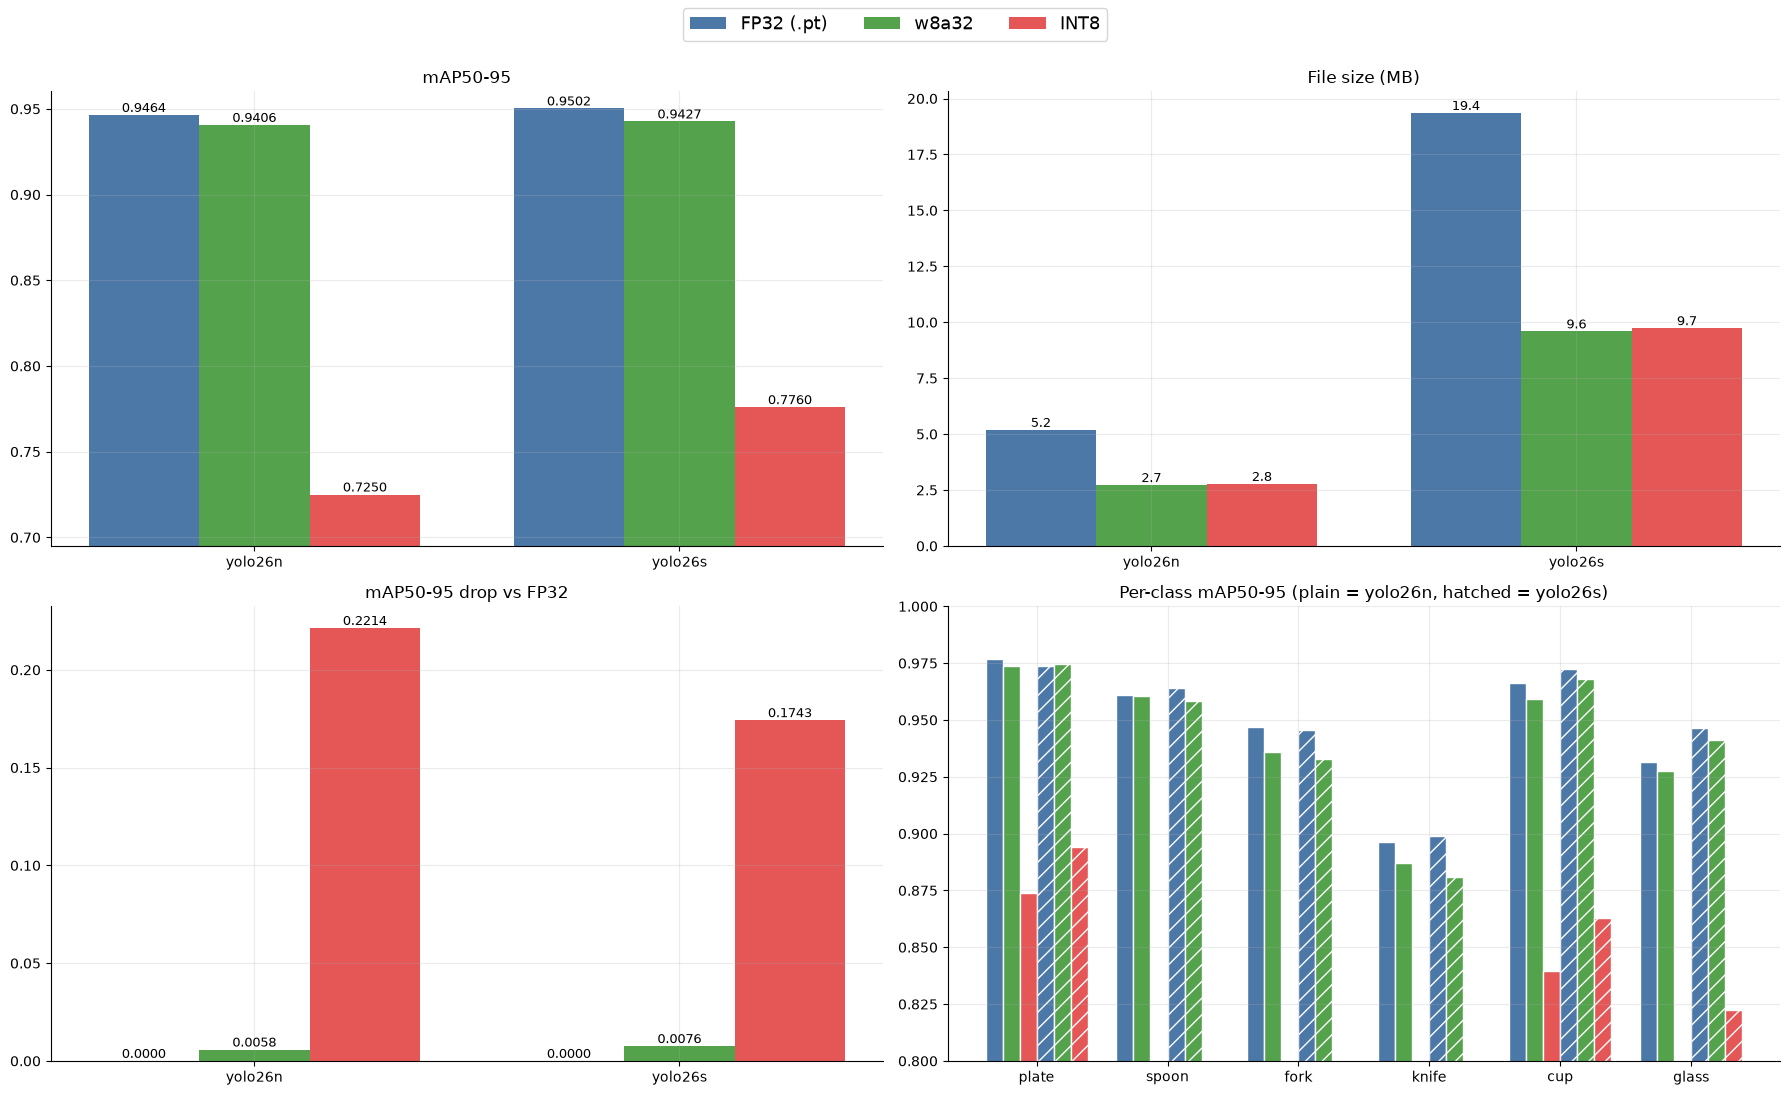

In [6]:
variants = list(VARIANT_COLORS)
x = np.arange(len(MODEL_NAMES))
width = 0.26

def pick(model, variant, column):
    return table[(table['model'] == model) & (table['variant'] == variant)][column].iloc[0]

def grouped_bars(ax, column, title, fmt):
    for i, variant in enumerate(variants):
        vals = [pick(m, variant, column) for m in MODEL_NAMES]
        bars = ax.bar(x + (i - 1) * width, vals, width, label=variant, color=VARIANT_COLORS[variant])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v), ha='center', va='bottom', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_NAMES)
    ax.set_title(title)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
grouped_bars(axes[0, 0], 'map5095', 'mAP50-95', '{:.4f}')
axes[0, 0].set_ylim(table['map5095'].min() - 0.03, table['map5095'].max() + 0.01)
grouped_bars(axes[0, 1], 'size_mb', 'File size (MB)', '{:.1f}')
grouped_bars(axes[1, 0], 'drop_vs_fp32', 'mAP50-95 drop vs FP32', '{:.4f}')

# per-class panel: colour = variant, plain bar = yolo26n, hatched bar = yolo26s
ax = axes[1, 1]
cx = np.arange(len(CLASS_NAMES))
bar_w = 0.13
slot = 0
for m_idx, model in enumerate(MODEL_NAMES):
    for variant in variants:
        vals = np.array(pick(model, variant, 'per_class'))
        ax.bar(cx + (slot - 2.5) * bar_w, vals, bar_w, color=VARIANT_COLORS[variant],
               hatch='//' if m_idx else None, edgecolor='white')
        slot += 1
ax.set_xticks(cx)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0.8, 1.0)
ax.set_title('Per-class mAP50-95 (plain = yolo26n, hatched = yolo26s)')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, fontsize=13, frameon=True)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(PLOT_DIR / 'comparison_grid.png', dpi=130)
plt.show()


## Zip everything

In [7]:
!pip freeze > requirements.txt

/usr/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


In [8]:
BUNDLE = SAVE_DIR / 'kitchenware_bundle.zip'

# persistent copies first
shutil.copytree(EXPORT_DIR, SAVE_DIR / 'exports', dirs_exist_ok=True)
shutil.copytree(PLOT_DIR, SAVE_DIR / 'plots', dirs_exist_ok=True)

with zipfile.ZipFile(BUNDLE, 'w', zipfile.ZIP_DEFLATED) as z:
    for name in MODEL_NAMES:
        run = RUNS_DIR / name
        if best_pt[name].exists():
            z.write(best_pt[name], f'{name}/best.pt')
        for f in ('results.csv', 'args.yaml'):
            if (run / f).exists():
                z.write(run / f, f'{name}/{f}')
        for png in run.glob('*.png'):
            z.write(png, f'{name}/plots/{png.name}')
    for f in EXPORT_DIR.iterdir():
        z.write(f, f'exports/{f.name}')
    for f in PLOT_DIR.iterdir():
        z.write(f, f'plots/{f.name}')
    z.write(DATA_YAML, 'kitchenware.yaml')

print(f'{BUNDLE}  ({BUNDLE.stat().st_size / 1024**2:.1f} MB)')

/workspace/kitchenware_results/kitchenware_bundle.zip  (45.3 MB)
